# Tracking Lunar Gateway with an uncontrolled halo observer

The uncontrolled halo observer is used to track Lunar Gateway using optical angle measurements. Three lunar surface observatories (LSOs) estimate the observer's orbit, while the observer measures Gateway. The analysis compares Gateway tracking with perfect and estimated knowledge of the observer's state, then examines how tracking degrades when the observer departs from the nominal halo and Gateway measurements become unavailable.

The long-term goal is to maintain **Gateway position-estimation error below 100 m** and **velocity-estimation error below 0.01 m/s**. The halo observer can tolerate a much larger departure from its nominal orbit as long as Gateway tracking remains accurate. The figures below establish the uncontrolled baseline. Later sections generate executed-burn trajectories for training and testing a nonlinear ARX guidance model.

In [1]:
from pathlib import Path
import sys
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "configs/baseline.json").exists() and (p / "pyproject.toml").exists()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from within the project checkout")
sys.path.insert(0, str(ROOT / "src"))
from halo_tracking.study import load_config
cfg = load_config(ROOT / "configs/baseline.json")
cfg["simulation"]["periods"] = 1.0  # One nominal observer period


## 1. Tracking comparison and assumptions

The same uncontrolled halo observer and Lunar Gateway trajectories are used in both tracking cases. The difference is how accurately the observer's position is known.

| Assumption | Exact observer state | LSO-estimated observer state |
|---|---|---|
| Observer position available to the tracking filter | Simulated truth | Estimated from three lunar surface stations |
| Initial observer uncertainty | None | 1 km and 0.1 m/s per axis (1σ) |
| Initial Gateway uncertainty | 1 km and 0.1 m/s per axis (1σ) | Same |
| Gateway measurements | Observer-to-Gateway angles | Same angles and noise |
| LSO measurements | Not required | Three-site angle measurements |

The observation cadence is 30 minutes. Lunar occultation, elevation limits, Sun/Earth keep-outs and instrument range limits determine which optical measurements are available. The Gateway estimates are compared against the same simulated truth, so differences in tracking error can be attributed to observer-state knowledge in this matched comparison.

In [2]:
from IPython.display import HTML, Markdown, display
settings = [
    ("Duration", f"1 observer nominal period = {cfg['orbit']['period_tu'] * cfg['time_unit_s'] / 86400:.2f} days"),
    ("Observer initial position / velocity 1σ", f"{cfg['estimation']['initial_position_sigma_km']:g} km / {1000*cfg['estimation']['initial_velocity_sigma_km_s']:g} m/s per axis"),
    ("Gateway initial position / velocity 1σ", f"{cfg['comparison']['gateway_position_sigma_km']:g} km / {1000*cfg['comparison']['gateway_velocity_sigma_km_s']:g} m/s per axis"),
    ("LSO angular noise 1σ", f"{cfg['measurement']['angle_sigma_arcsec']:g} arcsec per angle"),
    ("Gateway camera angular noise 1σ", f"{cfg['comparison']['gateway_camera_sigma_arcsec']:g} arcsec per angle")]
display(HTML("<table>"+"".join(f"<tr><th>{name}</th><td>{value}</td></tr>" for name,value in settings)+"</table>"))

Duration,1 observer nominal period = 8.06 days
Observer initial position / velocity 1σ,1 km / 0.1 m/s per axis
Gateway initial position / velocity 1σ,1 km / 0.1 m/s per axis
LSO angular noise 1σ,1 arcsec per angle
Gateway camera angular noise 1σ,1 arcsec per angle


In [3]:
from halo_tracking.gateway_comparison import run_gateway_comparison, save_comparison
result = run_gateway_comparison(cfg)
report = save_comparison(result, ROOT / "results/gateway_comparison")

/home/runner/work/Halo_Orbit_Tracking/Halo_Orbit_Tracking/src/halo_tracking/gateway_comparison.py:136: UserWarning: Supplied rounded state does not close within 1 km. Treat as an initial-value trajectory, not a validated periodic halo.
  truth=make_truth(cfg, extra_times=boundaries)


## 2. Three lunar observatories estimate the halo observer

The three LSOs observe the halo spacecraft from different locations on the Moon. Their angular measurements allow the observer's orbit to be estimated even though its initial state is uncertain. The geometry plot shows the Moon, observer and Gateway trajectories. The following plot compares the estimated observer orbit with its true simulated trajectory.

The observer's orbit is the same in the perfect-knowledge and estimated-knowledge cases. Only the quality of the information available to the Gateway tracking filter changes. The network uses three stations to improve observation coverage; the current experiment does not establish that three stations are the minimum required.

The optical measurement is an azimuth/elevation pair:

$$
\mathbf{z}_{k}=h(\mathbf{x}_{k})+\boldsymbol{\eta}_{k},\qquad
\boldsymbol{\eta}_{k}\sim\mathcal{N}(\mathbf{0},R).
$$

Only measurements that pass the elevation, occultation and keep-out checks update the observer estimate. The estimated uncertainty is obtained from the filter covariance, while the actual error is measured against simulated truth.

findfont: Failed to find font weight bold for STIXSizeFiveSym, now using 400.


findfont: Failed to find font weight bold for cmmi10, now using 400.


findfont: Failed to find font weight bold for cmsy10, now using 400.


findfont: Failed to find font weight bold for cmr10, now using 400.


findfont: Failed to find font weight bold for cmtt10, now using 400.


findfont: Failed to find font weight bold for cmti10, now using 400.


findfont: Failed to find font weight bold for cmb10, now using 400.


findfont: Failed to find font weight bold for cmss10, now using 400.


findfont: Failed to find font weight bold for cmex10, now using 400.


findfont: Failed to find font weight bold for DejaVu Sans Display, now using 400.


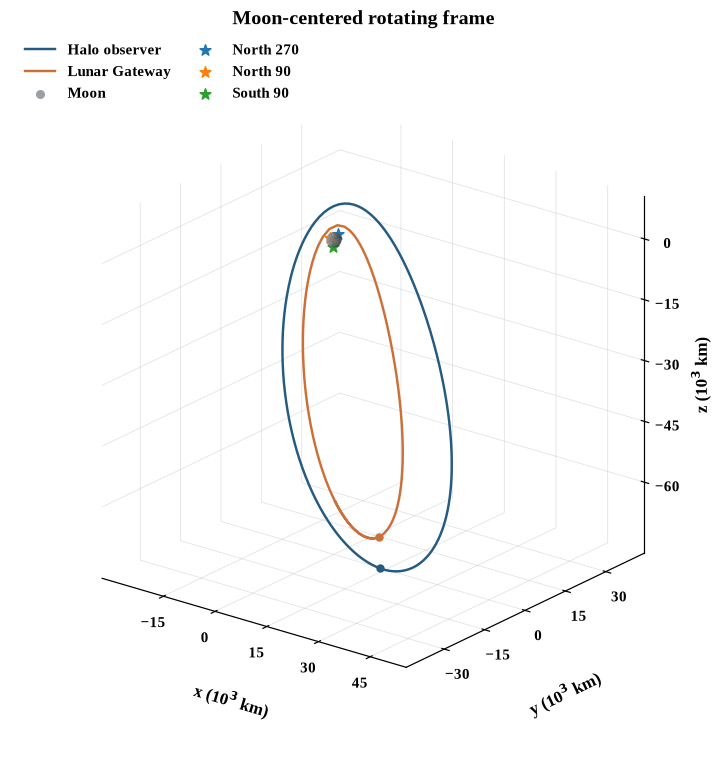

In [4]:
from halo_tracking.plotting import geometry, observer_knowledge, gateway_comparison_figures, state_histories, export
fig_geometry = geometry(result)
export(fig_geometry, ROOT / "results/gateway_comparison/geometry.png")

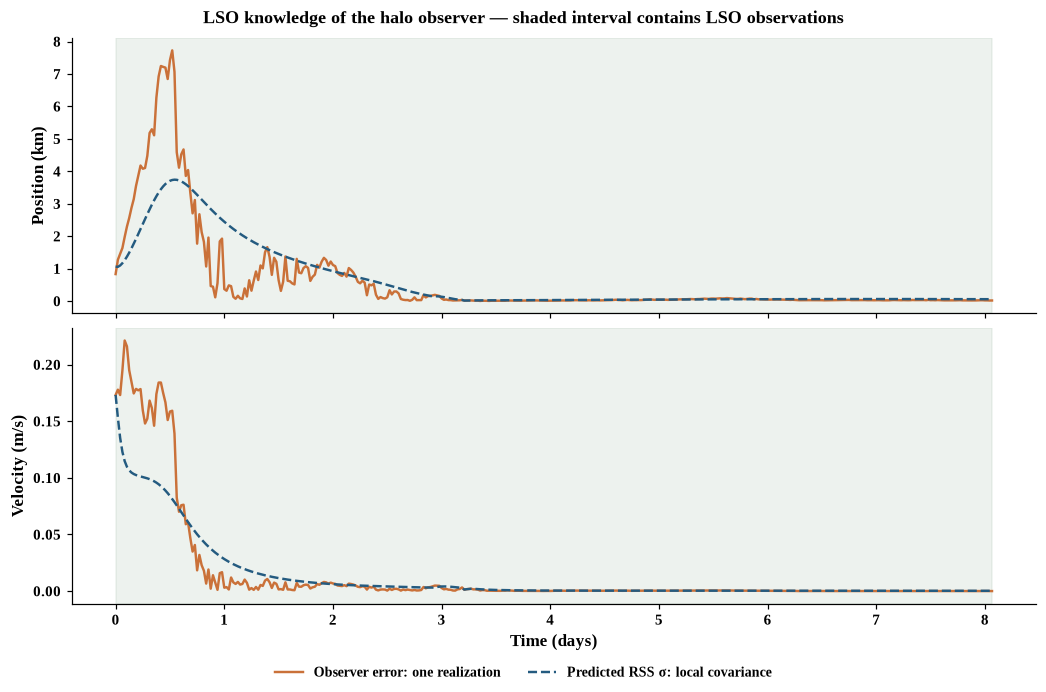

In [5]:
fig_observer = observer_knowledge(result)
export(fig_observer, ROOT / "results/gateway_comparison/observer.png")

## Observer trajectory and estimation error

The following figure compares the observer's true position, velocity and acceleration with its LSO-based estimate. Both trajectories are plotted in Moon-centered inertial coordinates. Their differences are small compared with the orbit dimensions, so the component plots can appear nearly identical even when the estimation error is measurable.

The error and uncertainty plots above are needed to assess observer navigation performance.

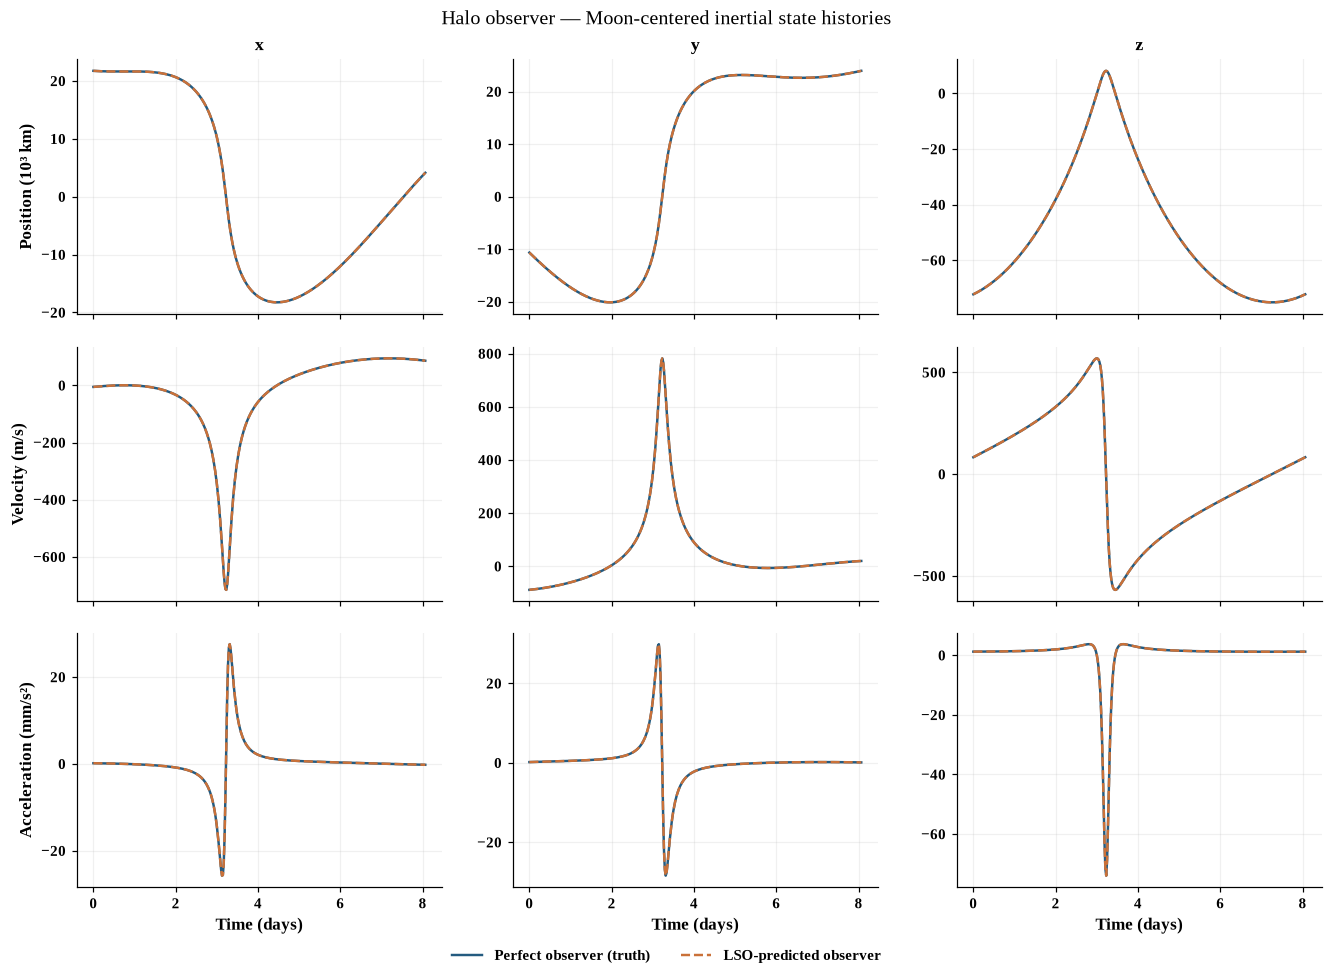

In [6]:
fig_observer_states = state_histories(result, 'observer')
export(fig_observer_states, ROOT / 'results/gateway_comparison/observer_states.png')

## Gateway trajectory and estimation error

The figure below compares Gateway's true position, velocity and acceleration against the orbit estimates obtained with exact and LSO-estimated observer states. The state components provide the orbital context. The tracking error figure in the next section resolves the differences between the two solutions.

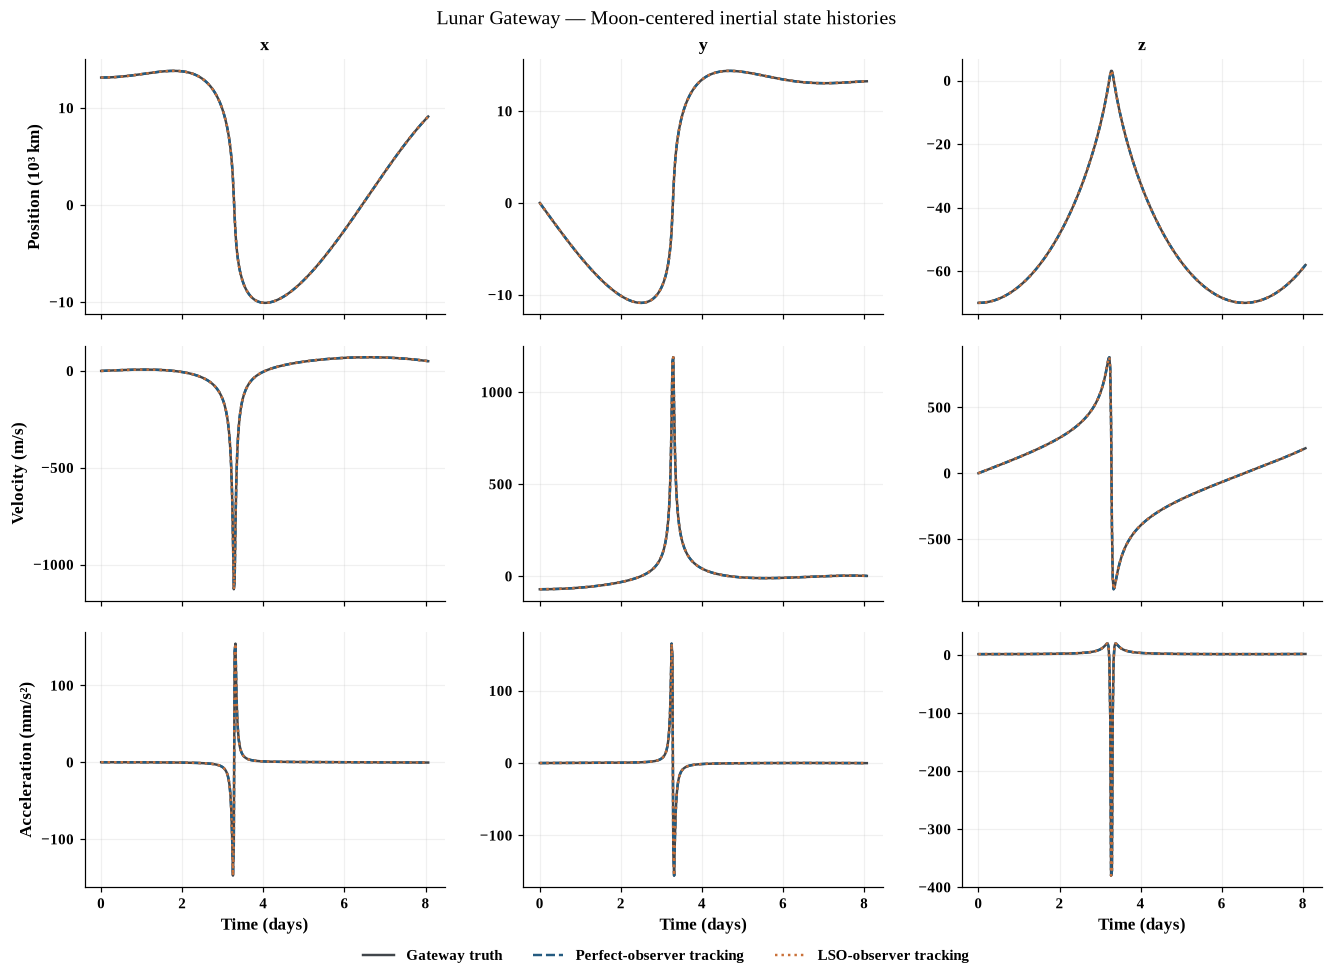

In [7]:
fig_gateway_states = state_histories(result, 'gateway')
export(fig_gateway_states, ROOT / 'results/gateway_comparison/gateway_states.png')

## 3. Effect of observer uncertainty on Gateway tracking

The uncontrolled halo observer measures Gateway using the same simulated optical observations in both cases. In the first case its true position is known. In the second case its position is estimated using the three LSOs. The two curves therefore show how uncertainty in the observing spacecraft affects Gateway orbit determination.

The relevant tracking errors are

$$
e_{r,G}(t)=\left\|\hat{\mathbf r}_G(t)-\mathbf r_G(t)\right\|,\qquad
e_{v,G}(t)=\left\|\hat{\mathbf v}_G(t)-\mathbf v_G(t)\right\|.
$$

The position and velocity errors below should be compared directly between the two cases. The covariance plot describes the filter's estimated uncertainty; the actual-error plot determines whether tracking accuracy is maintained. Errors are shown in physical Moon-centered inertial coordinates.

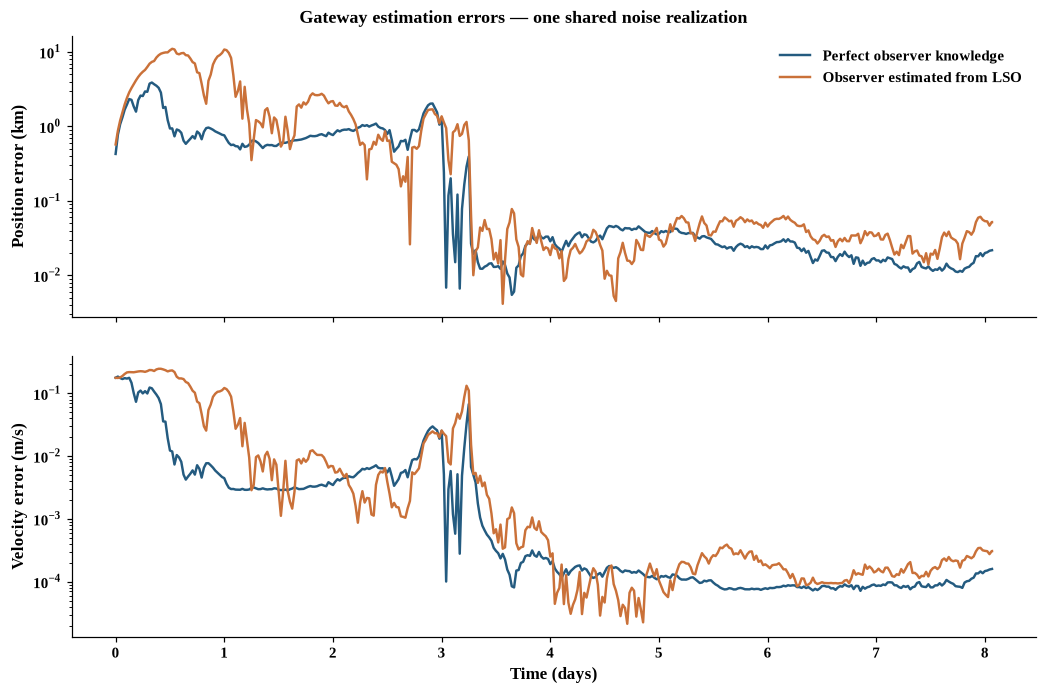

In [8]:
figures = gateway_comparison_figures(result)
fig_errors = figures["errors"]
export(fig_errors, ROOT / "results/gateway_comparison/errors.png")
import matplotlib.pyplot as plt
plt.close(figures["uncertainty"])

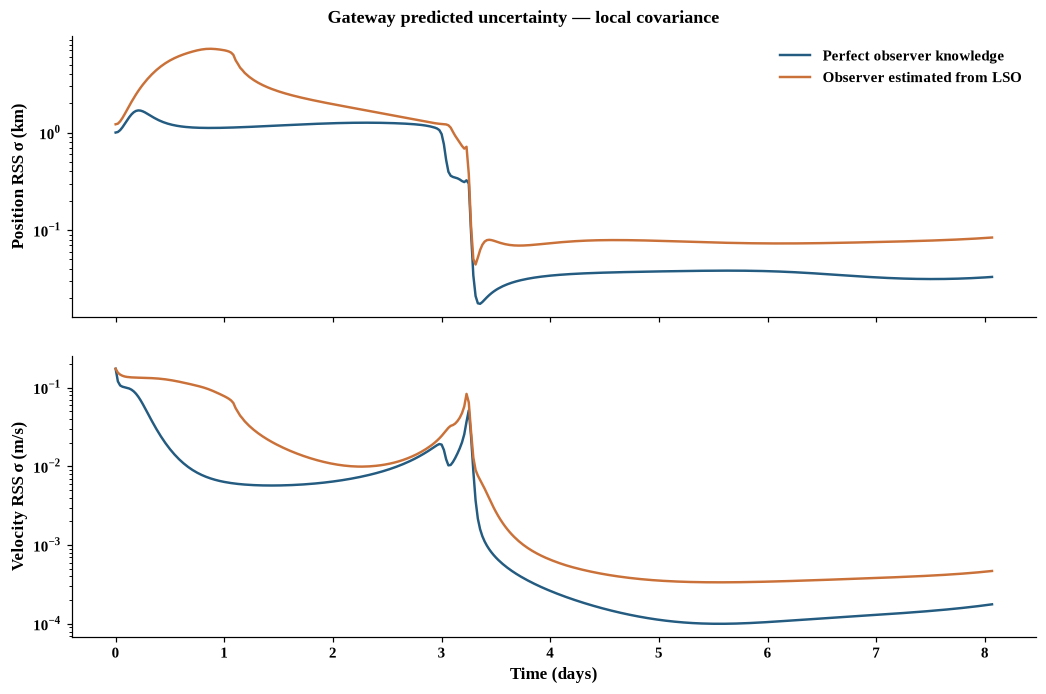

In [9]:
figures_uncertainty = gateway_comparison_figures(result)
plt.close(figures_uncertainty["errors"])
fig_uncertainty = figures_uncertainty["uncertainty"]
export(fig_uncertainty, ROOT / "results/gateway_comparison/uncertainty.png")

## Dynamics and estimation assumptions

Both spacecraft are propagated under the Earth–Moon CR3BP. Position and velocity histories are reported in Moon-centered inertial coordinates. The plotted acceleration is calculated from the modeled equations of motion rather than measured independently.

Three LSO sites provide the observer's angular measurements. Gateway measurements are made from the halo spacecraft. The tracking filters retain observer–Gateway covariance coupling but Gateway optical updates do not directly correct the observer state. The numerical results apply to the stated geometry, noise, observation masks and force model.

## 4. Why the uncontrolled halo departs from its reference orbit

The halo observer begins at the rounded SNRHL2 catalog state and is propagated continuously without station-keeping. Because the catalog coordinates are rounded, the resulting trajectory does not close after one period. A nearby initial state is corrected numerically to form the periodic halo reference used for comparison.

The corrected reference returns approximately to the same state every period, but the orbit is **linearly unstable**. Small differences between the uncontrolled spacecraft and the periodic reference can grow with time. The reference-departure metric is

$$
\delta\mathbf{x}_O(t)=\mathbf{x}_{O,\mathrm{uncontrolled}}(t)
-\mathbf{x}_{O,\mathrm{reference}}(t).
$$

The following figures measure how far the uncontrolled spacecraft moves from that periodic orbit. This is not the observer-to-Gateway distance, and it is not Gateway tracking error. The departure matters because it changes the geometry and availability of measurements used for Gateway tracking. The 100 km / 1 m/s observer corridor is deliberately less restrictive than the 100 m / 0.01 m/s Gateway tracking target.

## Stability of the corrected nominal NRHO

This diagnostic evaluates the **corrected periodic nominal orbit**. It is separate from the uncontrolled catalog-seed departure. Integrating the variational equations

$$
\dot{\Phi}(t)=A(t)\Phi(t), \qquad \Phi(0)=I
$$

over one corrected period $T$ gives the **monodromy matrix** $M=\Phi(T)$. Its eigenvalues $\lambda_i$ are **Floquet multipliers**. Their largest magnitude is the **spectral radius**

$$
\rho(M)=\max_i |\lambda_i|.
$$

A multiplier with magnitude greater than one indicates a linearly unstable mode. In that mode, the perturbation amplitude is multiplied by $|\lambda_i|$ after each period at matching orbital phase. A negative real multiplier also reverses the mode's sign each period. This does not mean every initial perturbation or physical error grows by the same factor at every epoch.

For $\rho(M)>1$, the dominant local modal **e-folding time** is

$$
\tau=\frac{T}{\ln\rho(M)}.
$$

It is the timescale for the dominant mode's exponential envelope to grow by a factor of $e$. It is not a maneuver deadline or a prediction of total navigation error. A small **closure error** means the reference returns close to its starting state after one period. It does not establish stability of nearby trajectories.

A second integration checks sensitivity to solver tolerances. The code requires adequate reference closure and a spectral-radius margin before reporting instability. Near-unit results remain unresolved. Unit-circle multipliers alone do not prove nonlinear stability, and repeated unit multipliers require additional care.

The ensemble below starts around the **corrected nominal state**, with seeded 1-km / 0.01-m/s per-axis perturbations and no burns. Its 100-km / 1-m/s corridor is an exploratory requirement independent of the Floquet classification. Non-exits are censored at the study end. Finite-horizon boundedness does not establish nonlinear stability or a quasi-stability classification.

Reference: [NASA's geometrical analysis of station-keeping using Floquet modes](https://ntrs.nasa.gov/citations/20220005226).

Multiplier,Real,Imaginary,Magnitude
1,-3.047937,+0.000000,3.047937
2,-0.328091,+0.000000,0.328091
3,+1.000021,+0.000000,1.000021
4,+0.999979,+0.000000,0.999979
5,+0.312320,+0.949977,1.000000
6,+0.312320,-0.949977,1.000000


**Nominal-orbit result: linearly unstable.** Largest multiplier magnitude: **3.047937**. local e-folding time: **7.23 days**. The spectral radius changes by 1.20e-08 between solver tolerances. One-period position closure is 8.08e-08 km. Near-unit neutral multipliers can split numerically. The classification uses a margin and a closure check, not exact equality to one.

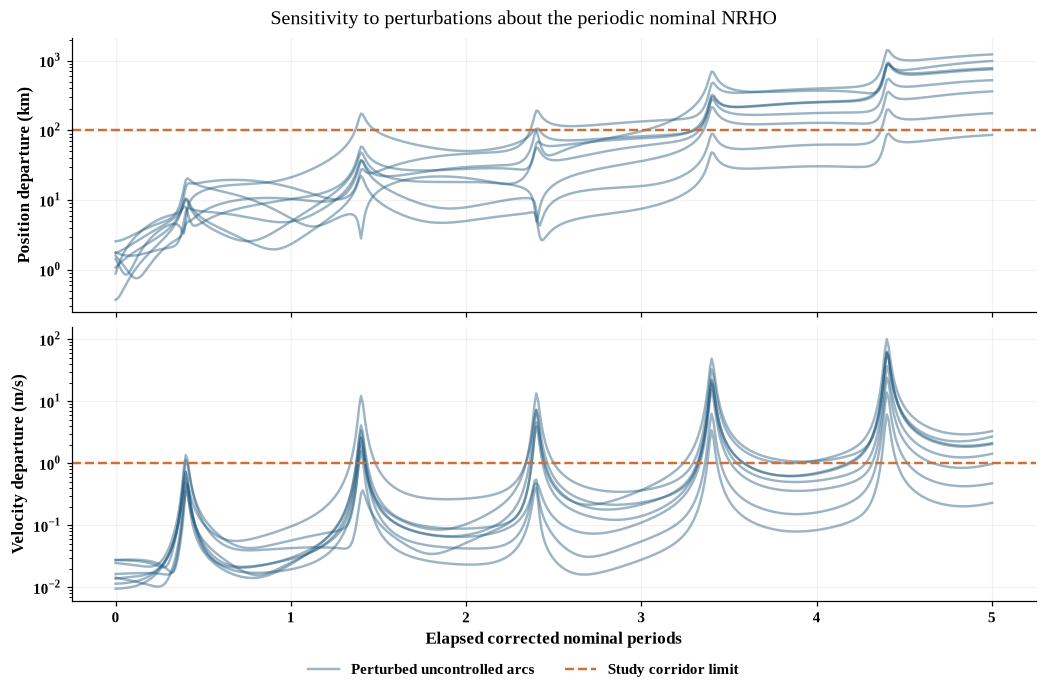

**Finite-horizon result:** 8 of 8 perturbed arcs leave the study corridor within 5 nominal periods. Crossings are detected at sampled epochs. These deviations help expose tracking sensitivity and supply corrective ΔV cases. They do not establish successful maneuver execution or recovery. Diagnostics and histories are saved under `results/stability/`.

In [10]:
import numpy as np
from halo_tracking.stability import orbit_stability, save_stability
stability = orbit_stability(cfg, periods=5, ensemble_count=8)
save_stability(stability, ROOT / 'results/stability')
stab = stability['summary']
multiplier_rows = ''.join(
    f"<tr><td>{i+1}</td><td>{v['real']:+.6f}</td>"
    f"<td>{v['imag']:+.6f}</td><td>{v['magnitude']:.6f}</td></tr>"
    for i, v in enumerate(stab['floquet_multipliers']))
display(HTML('<table><tr><th>Multiplier</th><th>Real</th>'
             '<th>Imaginary</th><th>Magnitude</th></tr>' + multiplier_rows + '</table>'))
tau = stab['efolding_time_days']
timescale = f'{tau:.2f} days' if tau is not None else 'not established'
display(Markdown(
    f"**Nominal-orbit result: {stab['classification']}.** "
    f"Largest multiplier magnitude: **{stab['spectral_radius']:.6f}**. "
    f"local e-folding time: **{timescale}**. "
    f"The spectral radius changes by {stab['spectral_radius_tolerance_change']:.2e} "
    f"between solver tolerances. One-period position closure is "
    f"{stab['position_closure_km']:.2e} km. "
    "Near-unit neutral multipliers can split numerically. The classification "
    "uses a margin and a closure check, not exact equality to one."
))

fig, axes = plt.subplots(2, 1, figsize=(9.4, 6.2), sharex=True, layout='constrained')
for ax, key, limit, label in zip(
        axes, ['position_departure_km', 'velocity_departure_m_s'],
        [stab['position_limit_km'], stab['velocity_limit_m_s']],
        ['Position departure (km)', 'Velocity departure (m/s)']):
    for i, history in enumerate(stability[key]):
        ax.semilogy(stability['times_tu']/stab['period_tu'],
                    np.maximum(history, 1e-12), color='#245b80', alpha=.45,
                    label='Perturbed uncontrolled arcs' if i == 0 else None)
    ax.axhline(limit, color='#ca7139', ls='--', label='Study corridor limit')
    ax.set_ylabel(label)
    ax.grid(alpha=.17)
axes[-1].set_xlabel('Elapsed corrected nominal periods')
fig.suptitle('Sensitivity to perturbations about the periodic nominal NRHO')
fig.legend(*axes[0].get_legend_handles_labels(), loc='outside lower center',
           ncol=2, frameon=False)
export(fig, ROOT / 'results/stability/nominal_perturbation_departure.png')
display(fig)
plt.close(fig)
display(Markdown(
    f"**Finite-horizon result:** {stab['arcs_with_sampled_corridor_exit']} of "
    f"{stab['ensemble_count']} perturbed arcs leave the study corridor within "
    f"{stab['periods']} nominal periods. Crossings are detected at sampled epochs. "
    "These deviations help expose tracking sensitivity and supply corrective ΔV "
    "cases. They do not establish successful maneuver execution or recovery. "
    "Diagnostics and histories are saved under `results/stability/`."
))

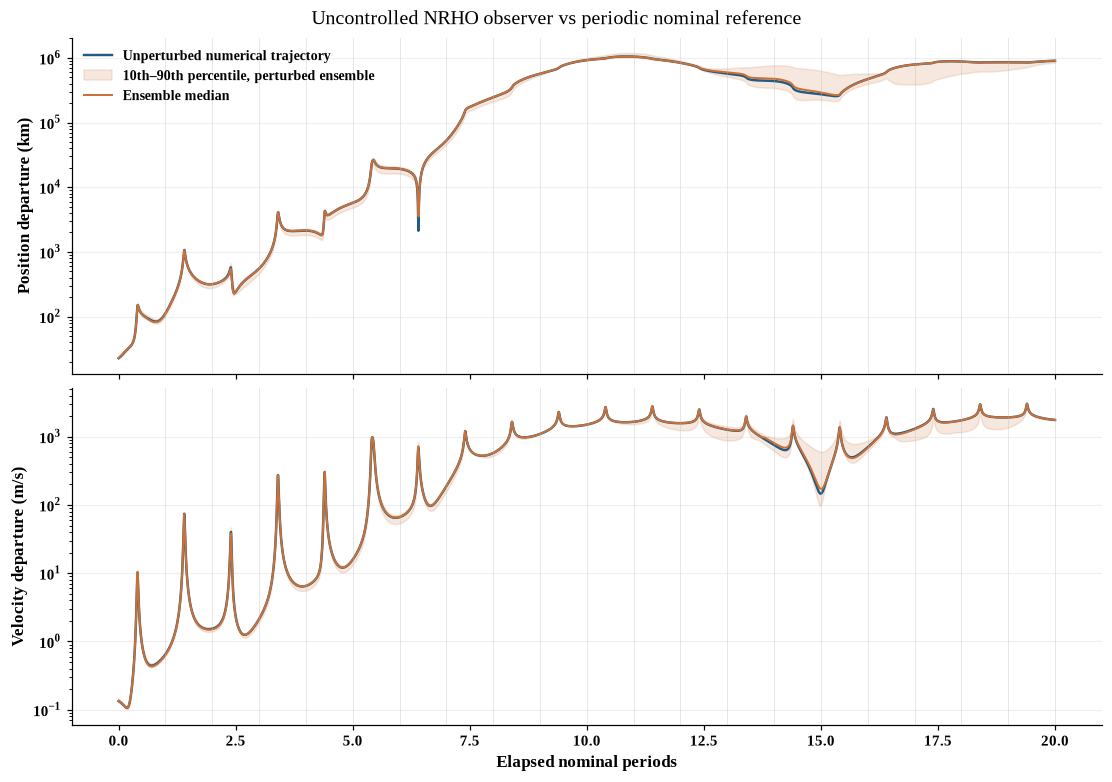

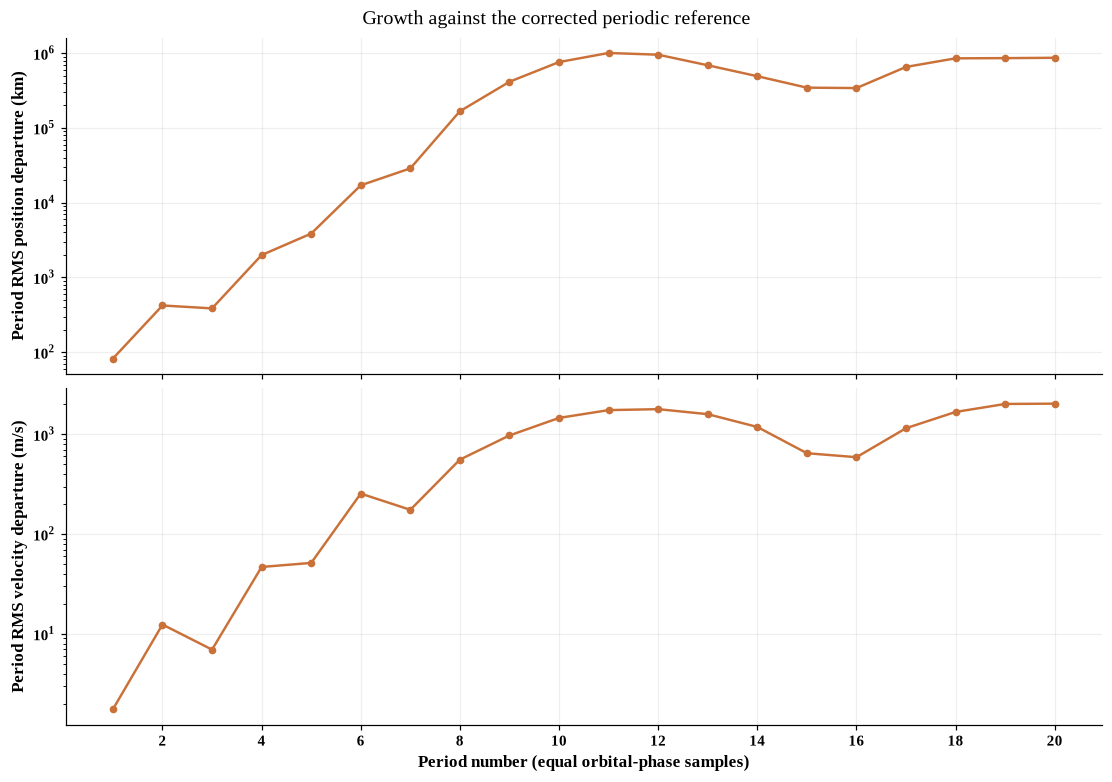

In [11]:
from halo_tracking.departure import reference_departure, save_departure
from halo_tracking.plotting import departure_figures
departure = reference_departure(cfg, periods=20, ensemble_count=8)
save_departure(departure, cfg, ROOT / 'results/departure')
departure_plots = departure_figures(departure, cfg)
export(departure_plots['departure'], ROOT / 'results/departure/departure.png')
export(departure_plots['period_growth'], ROOT / 'results/departure/period_growth.png')

In [12]:
closure = departure['diagnostics']
periods = [1, 2, 4, 6, 8, 10, 20]
rows = ''.join(f"<tr><td>{k-1}T → {k}T</td><td>{departure['period_position_rms_km'][k-1]:,.1f}</td>"
               f"<td>{departure['period_velocity_rms_m_s'][k-1]:,.3f}</td></tr>" for k in periods)
display(HTML('<table><tr><th>Period interval</th><th>RMS position departure (km)</th>'
             '<th>RMS velocity departure (m/s)</th></tr>' + rows + '</table>'))
display(Markdown(f"""
The corrected **nominal** one-period closure is **{closure['position_closure_km']:.6f} km** and **{closure['velocity_closure_m_s']:.6f} m/s**. The original rounded **catalog** state's one-period closure error is **{closure['catalog_closure_km']:.1f} km**. The initial rounded truth-to-nominal position offset is **{closure['initial_nominal_offset_km']:.1f} km**.

Each RMS value covers that period alone. Departure can decrease temporarily as the geometry changes. This does not establish stabilization. The guidance section below uses exploratory trigger and corridor values, not operational limits.
"""))

display(Markdown(
    f"**Departure trend:** period RMS grows from "
    f"{departure['period_position_rms_km'][0]:,.1f} km in period 1 to "
    f"{departure['period_position_rms_km'][-1]:,.1f} km in period 20. "
    "The long-horizon motion has left the nominal halo neighborhood. "
    "it illustrates uncontrolled CR3BP divergence, not a maintained orbit."
))


Period interval,RMS position departure (km),RMS velocity departure (m/s)
0T → 1T,82.2,1.753
1T → 2T,422.0,12.401
3T → 4T,"1,994.5",46.829
5T → 6T,"17,104.5",254.631
7T → 8T,"167,666.4",558.081
9T → 10T,"762,607.6","1,461.219"
19T → 20T,"869,682.8","2,030.756"



The corrected **nominal** one-period closure is **0.000008 km** and **0.000000 m/s**. The original rounded **catalog** state's one-period closure error is **99.1 km**. The initial rounded truth-to-nominal position offset is **22.8 km**.

Each RMS value covers that period alone. Departure can decrease temporarily as the geometry changes. This does not establish stabilization. The guidance section below uses exploratory trigger and corridor values, not operational limits.


**Departure trend:** period RMS grows from 82.2 km in period 1 to 869,682.8 km in period 20. The long-horizon motion has left the nominal halo neighborhood. it illustrates uncontrolled CR3BP divergence, not a maintained orbit.

## 5. Growth of the uncontrolled halo departure

Each panel follows the **same continuously propagated uncontrolled halo spacecraft**, beginning at the catalog state and extending to the indicated number of reference periods. The dashed curve is the corrected periodic halo reference. The figures demonstrate how the physical observer departs from its intended repeating orbit without maneuvers.

The annotations report the largest reference departure reached over each accumulated interval. The changing plot scale makes the geometry readable as departure grows. Compare the fixed-scale figure to see how large the departure becomes relative to the nominal halo itself. This is the physical basis for the observer station-keeping trigger, not a Gateway tracking-error plot.

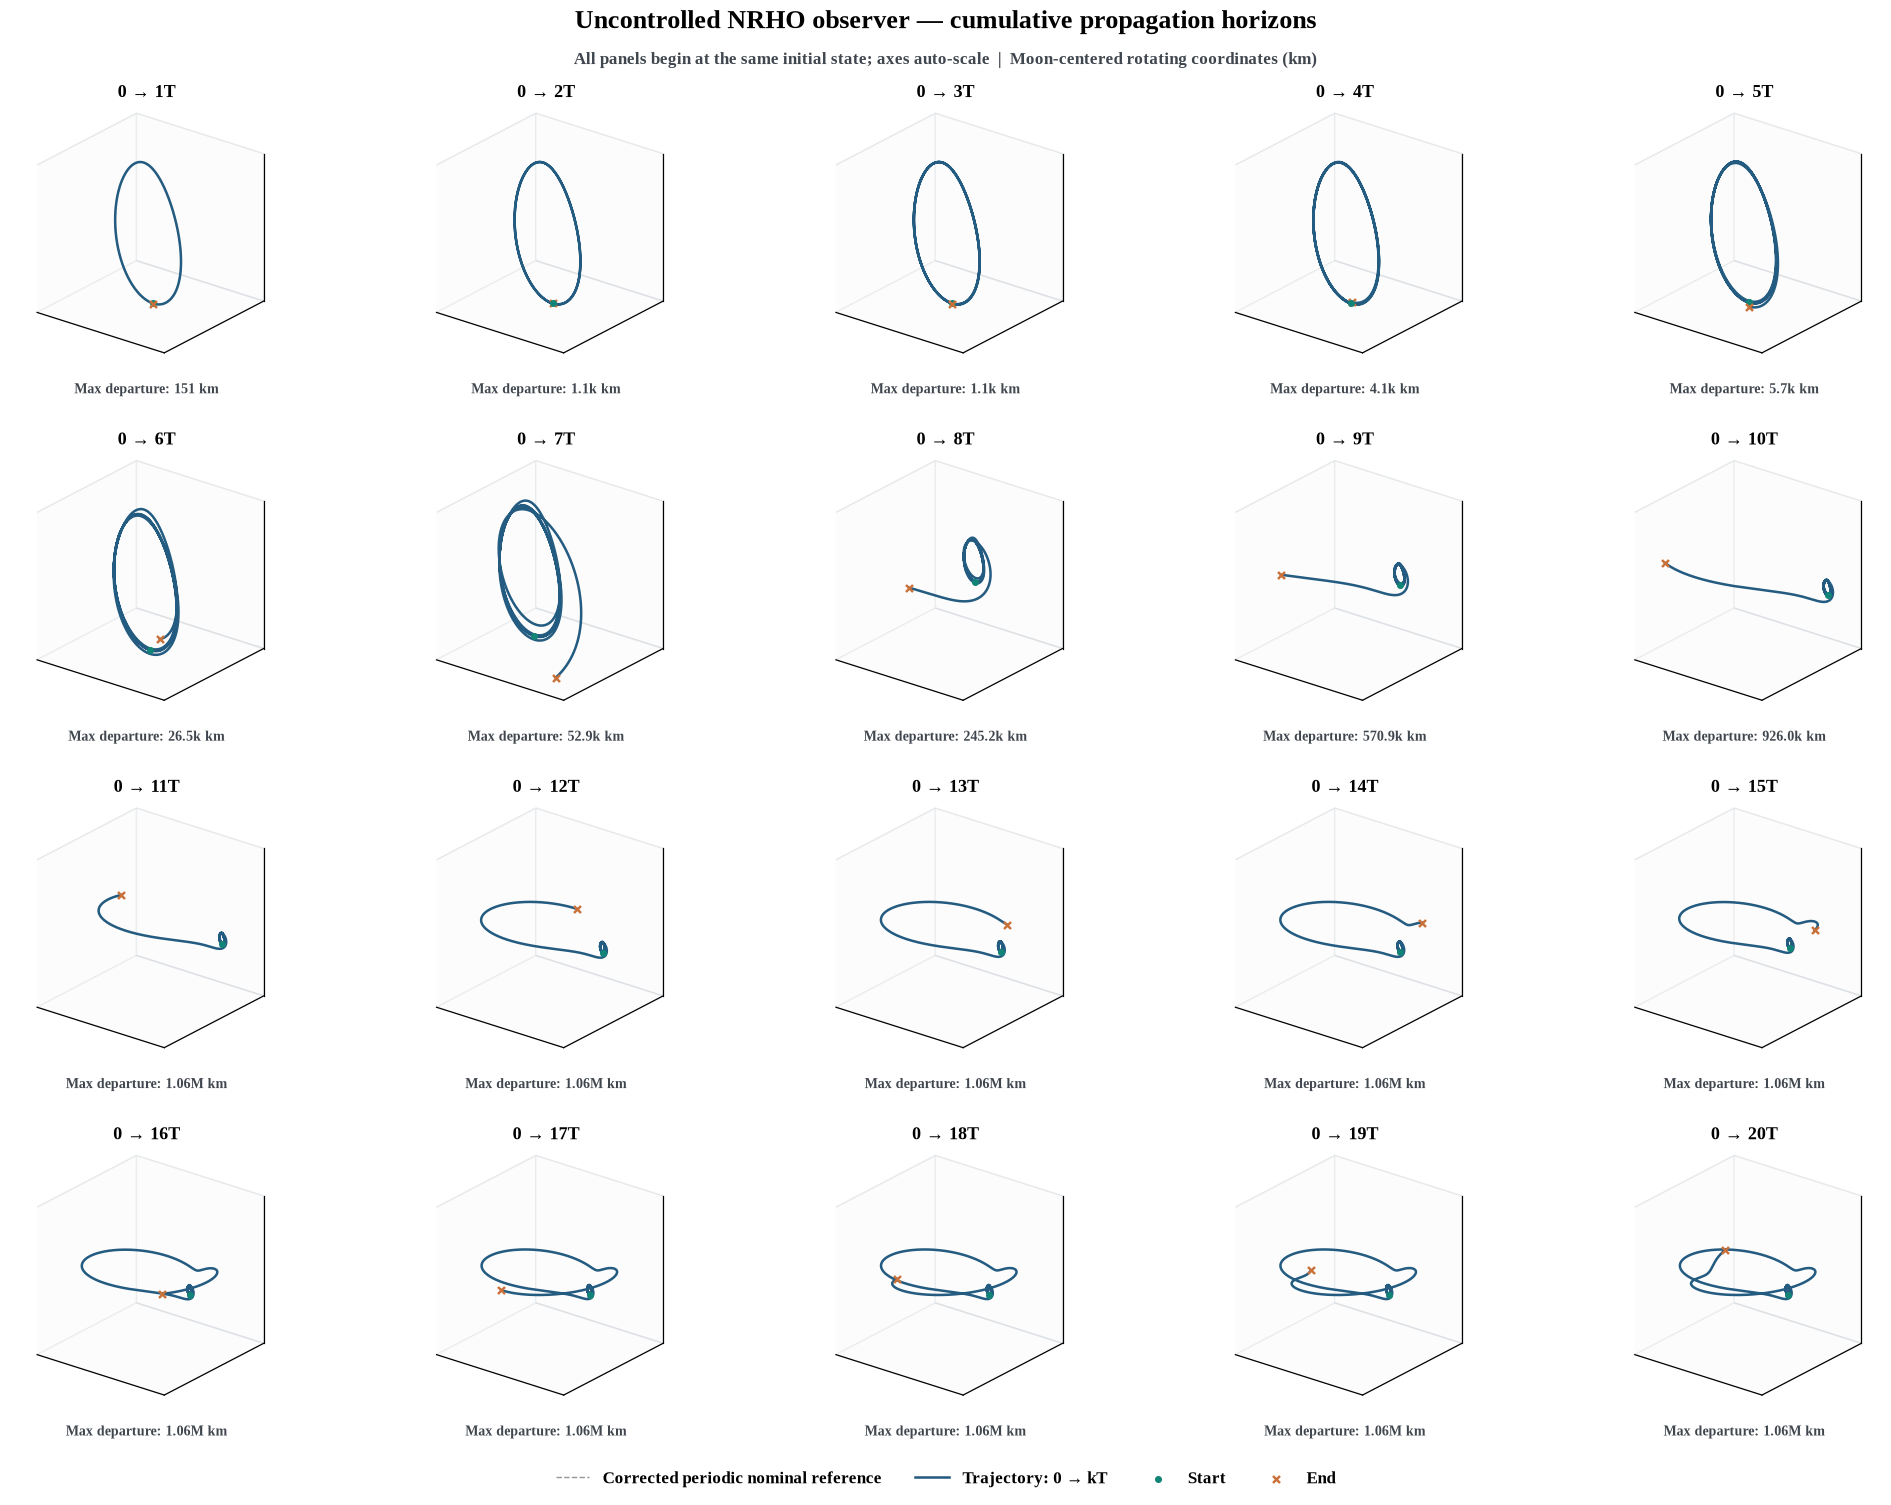

In [13]:
from halo_tracking.plotting import period_trajectory_grid
fig_period_grid = period_trajectory_grid(departure, cfg, scale_mode='local')
export(fig_period_grid, ROOT / 'results/departure/observer_period_grid.png')
display(fig_period_grid)
plt.close(fig_period_grid)

fig_reference_grid = period_trajectory_grid(departure, cfg, scale_mode='reference')
export(fig_reference_grid, ROOT / 'results/departure/observer_period_grid_fixed_scale.png')
plt.close(fig_reference_grid)

## 6. How Gateway tracking degrades without new measurements

The uncontrolled halo observer continues to track Gateway until the Gateway optical measurement link is disabled after eight observer periods. The table below shows how Gateway position-estimation error increases as the estimate is propagated without further Gateway observations. The rolling 24-hour RMSE measures the error over the most recent day instead of averaging across the entire experiment.

The simulated Gateway experiences a small acceleration that is absent from the estimator's CR3BP model. Consequently, its predicted and true trajectories drift apart during the observation gap. The three LSO sites can continue observing the halo spacecraft, but they do not directly measure Gateway. The comparison shows whether better knowledge of the observer is enough to reduce Gateway prediction error once the Gateway optical link is lost.

The **1, 10 and 100 km** entries describe when the simulated Gateway estimation error first exceeds those values. They illustrate the rate at which the uncontrolled tracking solution deteriorates; they are not the eventual **100 m / 0.01 m/s** performance requirements.

/home/runner/work/Halo_Orbit_Tracking/Halo_Orbit_Tracking/src/halo_tracking/gateway_comparison.py:136: UserWarning: Supplied rounded state does not close within 1 km. Treat as an initial-value trajectory, not a validated periodic halo.
  truth=make_truth(cfg, extra_times=boundaries)


Computed new truth-mismatch / forced-blackout prediction scenario.


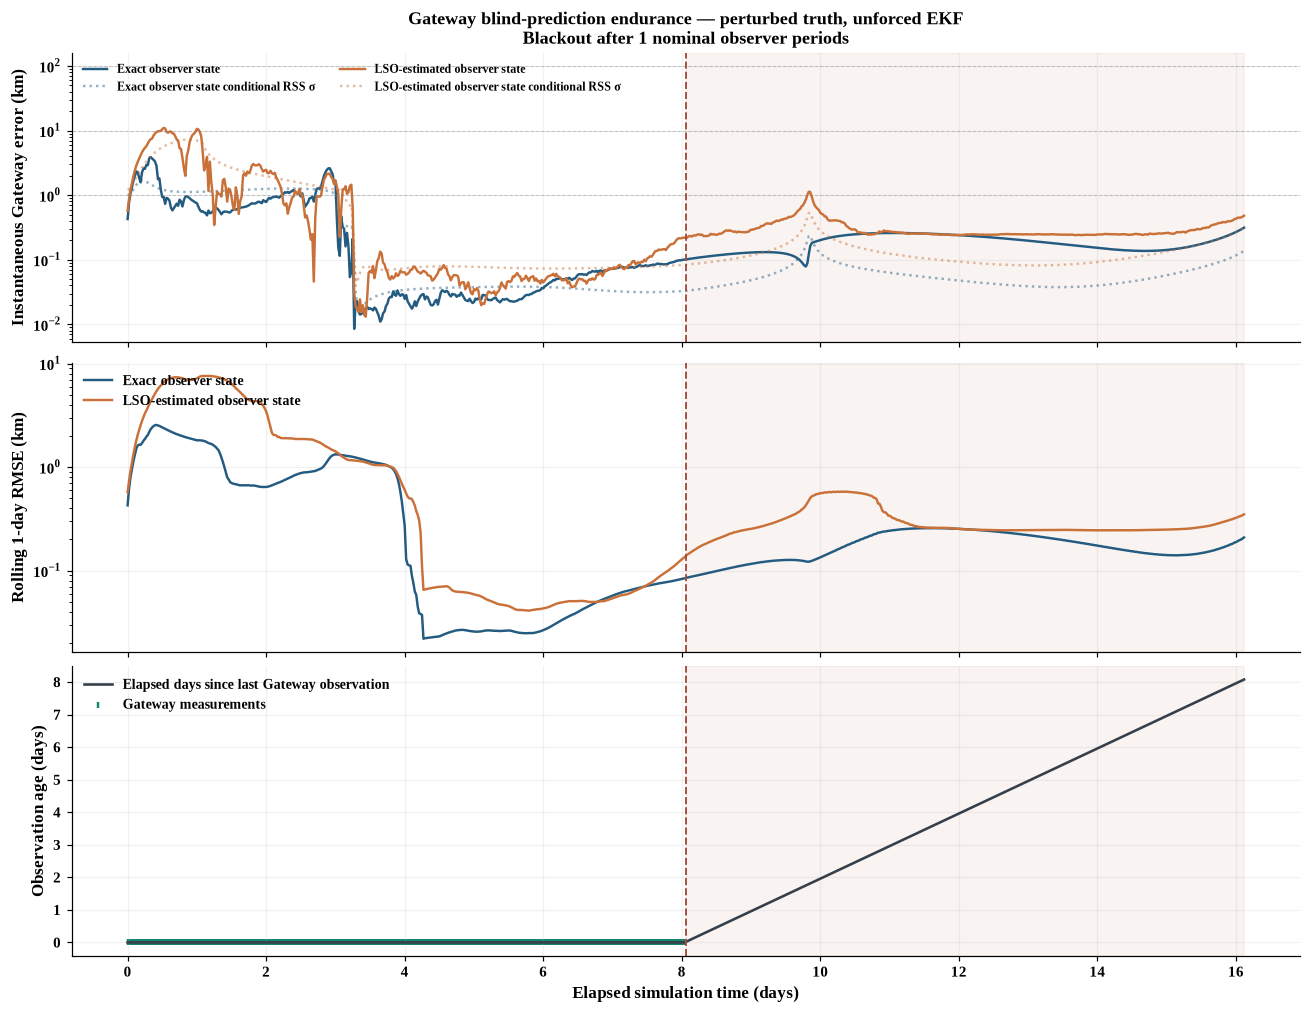

**Model mismatch:** 2.00e-09 m/s² fixed inertial direction. **forced blackout starts:** 8.06 days. **last accepted Gateway observation:** 8.041666666666666 days. The estimator uses unforced CR3BP throughout.

Horizon,New Gateway obs.,Days since last obs.,Exact obs. error (km),LSO obs. error (km),Exact obs. 24h RMSE (km),LSO obs. 24h RMSE (km)
0 → 1T,386,0.02,0.102,0.220,0.085,0.138
0 → 2T,0,8.07,0.314,0.481,0.209,0.350


Observer knowledge,Error tolerance (km),Days after last accepted Gateway observation
perfect,1,Not reached by study end
perfect,10,Not reached by study end
perfect,100,Not reached by study end
lso_estimated,1,1.77
lso_estimated,10,Not reached by study end
lso_estimated,100,Not reached by study end


**End-of-study errors:** exact-observer 0.31 km. LSO-estimated observer 0.48 km. Use the histories and threshold table to judge degradation. a temporary error decrease does not restart the prediction clock.

In [14]:
import numpy as np
import os
observer_period_count = int(os.environ.get('HALO_GATEWAY_PERIODS', '20'))

def render_metrics_table(title, headers, records):
    """Compact, horizontally scrollable table for blind prediction results."""
    headings = ''.join(
        '<th style="padding:8px 11px;text-align:right;'
        'background:#eef3f8;border-bottom:1px solid #cbd5e1;">'
        + str(label) + '</th>' for label in headers)
    rows = ''.join(
        '<tr style="background:' + ('#f6f8fc' if i%2 else 'white') + '">'
        + ''.join('<td style="text-align:right;padding:7px 11px;'
                  'border-bottom:1px solid #e5e9f0;white-space:nowrap;">'
                  + str(value) + '</td>' for value in record)
        + '</tr>' for i, record in enumerate(records))
    return (
        '<div style="margin:16px 0 6px;font-weight:600;">' + title +
        '</div><div style="overflow-x:auto;max-height:590px;'
        'border:1px solid #d5dde7;border-radius:8px;">'
        '<table style="border-collapse:collapse;min-width:800px;'
        'font:12px system-ui,sans-serif;font-variant-numeric:tabular-nums;">'
        '<thead><tr>' + headings + '</tr></thead><tbody>' + rows +
        '</tbody></table></div>')

from halo_tracking.gateway_prediction import (
    run_gateway_prediction_study, save_gateway_prediction_study,
    load_gateway_prediction_study
)
from halo_tracking.plotting import gateway_prediction_figure

prediction_periods = observer_period_count
blackout_period = min(int(os.environ.get('HALO_GATEWAY_BLACKOUT_PERIODS', '8')),
                      prediction_periods - 1)
truth_acceleration = float(os.environ.get(
    'HALO_GATEWAY_TRUTH_ACCELERATION_M_S2', '2e-9'))
prediction_output = ROOT / 'results/gateway_prediction'
prediction_kwargs = dict(
    periods=prediction_periods, blackout_period=blackout_period,
    disturbance_m_s2=truth_acceleration, rolling_window_days=1.,
    thresholds_km=(1., 10., 100.))
prediction = load_gateway_prediction_study(
    cfg, prediction_output, **prediction_kwargs)
if prediction is None:
    prediction = run_gateway_prediction_study(cfg, **prediction_kwargs)
    save_gateway_prediction_study(prediction, prediction_output)
    print('Computed new truth-mismatch / forced-blackout prediction scenario.')
else:
    print('Loaded matching saved prediction scenario and time histories.')

fig = gateway_prediction_figure(prediction)
export(fig, prediction_output / 'blind_prediction_endurance.png')
display(fig)
plt.close(fig)

summary = prediction['summary']
display(Markdown(
    f"**Model mismatch:** {summary['disturbance_m_s2']:.2e} m/s² fixed "
    f"inertial direction. **forced blackout starts:** "
    f"{summary['blackout_elapsed_days']:.2f} days. "
    f"**last accepted Gateway observation:** "
    f"{summary['last_accepted_gateway_observation_days']} days. "
    "The estimator uses unforced CR3BP throughout."
))

cols = ['Horizon', 'New Gateway obs.', 'Days since last obs.',
        'Exact obs. error (km)', 'LSO obs. error (km)',
        'Exact obs. 24h RMSE (km)', 'LSO obs. 24h RMSE (km)']
hrows = []
for k in range(1, prediction_periods + 1):
    pair = {r['case']: r for r in prediction['rows']
            if r['horizon_periods'] == k}
    a, b = pair['perfect'], pair['lso_estimated']
    age = a['days_since_gateway_observation']
    hrows.append([f'0 → {k}T', a['gateway_observations_latest_period'],
                  f'{age:.2f}' if np.isfinite(age) else 'No observation yet',
                  f"{a['instantaneous_position_error_km']:.3f}",
                  f"{b['instantaneous_position_error_km']:.3f}",
                  f"{a['rolling_position_rmse_km']:.3f}",
                  f"{b['rolling_position_rmse_km']:.3f}"])
display(HTML(render_metrics_table(
    'Gateway error at each cumulative-horizon endpoint', cols, hrows)))

limits_rows = []
for r in prediction['threshold_rows']:
    value = r['crossing_days_since_last_observation']
    when = (f'{value:.2f}' if value is not None
            else 'Not reached by study end')
    limits_rows.append([r['case'],
                        f"{r['position_threshold_km']:g}", when])
display(HTML(render_metrics_table(
    'First time position-error tolerance is exceeded after blackout',
    ['Observer knowledge', 'Error tolerance (km)',
     'Days after last accepted Gateway observation'], limits_rows)))

final = {r['case']: r for r in prediction['rows']
         if r['horizon_periods'] == prediction_periods}
display(Markdown(
    f"**End-of-study errors:** exact-observer "
    f"{final['perfect']['instantaneous_position_error_km']:,.2f} km. "
    f"LSO-estimated observer "
    f"{final['lso_estimated']['instantaneous_position_error_km']:,.2f} km. "
    "Use the histories and threshold table to judge degradation. "
    "a temporary error decrease does not restart the prediction clock."
))


## Summary and next analysis

The uncontrolled halo observer and the three-site LSO network provide the measurement geometry for tracking Lunar Gateway. The figures above show how observer-state uncertainty, departure from the corrected periodic halo, and loss of Gateway measurements affect the estimated Gateway orbit.

The station-keeping and machine-learning experiments are analyzed separately in [Notebook 01 — NARX Results](01_narx_results.ipynb). That notebook reports Monte Carlo maneuver histories, Gateway tracking after applied burns, and the two-stage maneuver-prediction results.